# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
NAMES = "Ali Powell, Olivia Teng, William Sutton"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

1 - For binary classification, we think that binary cross entropy would be appropriate to apply the first (binary classification), because it measures how well predicted probabilities match the actual labels. Strongly penalizes confident, wrong predictions to push the model in the right direction. For part 3, multi-class classification, you would use categorical cross-entrophy, which is classic to use for multi-class sorts, because it penalizes the model for assigning a low probability to the correct class. For the last one, regression, we would use MSE, because it averages squared prediction errors and penalizes large mistakes heavily, making it sensitive to outliers.

2 - For binary classification, we would use one output unit with a sigmoid activation function since it gives us a probability between 0 and 1. For multi-class classification, we would use three output units with a softmax activation function since we have three possible classes. Softmax gives us a probability for each class, and the one with the highest probability would be our prediction. For regression, we would use one output unit with no activation function because we're predicting a continuous value and don't want to limit the range of possible predictions.

3 - If features range numerically on different scales, ex some a 0-1 and others could be up to 10,000, there needs to be standardization. That difference in scale can make gradient descent harder to optimize. Standardization makes the feature scales more comparable, so that the network can train more consistently. We will split the data first, fit the scaler only on the training features, and use that same scaler to transform the holdout features to avoid data leakage.

4 - We can detect overfitting by seeing how our model performs on the training data compared to the holdout data. If the model continues to improve on the training data but starts to perform worse on the holdout data, then it may be memorizing the training examples instead of learning new patterns that may apply to new data. This growing difference between the two would suggest that our model is overfitting.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [ ]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [1]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# keeping seperate regression variables
X_reg = X.copy()
y_reg = y.copy()

X_reg_train, X_reg_holdout, y_reg_train, y_reg_holdout = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# fit scalers on training data only
reg_x_scaler = StandardScaler()
reg_y_scaler = StandardScaler()

X_reg_train_scaled = reg_x_scaler.fit_transform(X_reg_train)
X_reg_holdout_scaled = reg_x_scaler.transform(X_reg_holdout)

y_reg_train_scaled = reg_y_scaler.fit_transform(
    y_reg_train.reshape(-1, 1)
)
y_reg_holdout_scaled = reg_y_scaler.transform(
    y_reg_holdout.reshape(-1, 1)
)

# convert inputs/targets to tensors
X_reg_train_t = torch.tensor(X_reg_train_scaled, dtype=torch.float32)
X_reg_holdout_t = torch.tensor(X_reg_holdout_scaled, dtype=torch.float32)

y_reg_train_t = torch.tensor(y_reg_train_scaled, dtype=torch.float32)
y_reg_holdout_t = torch.tensor(y_reg_holdout_scaled, dtype=torch.float32)

print("Training-", X_reg_train_t.shape, y_reg_train_t.shape)
print("Holdout-", X_reg_holdout_t.shape, y_reg_holdout_t.shape)

Training- torch.Size([800, 2]) torch.Size([800, 1])
Holdout- torch.Size([200, 2]) torch.Size([200, 1])


In [2]:
# making the class
class RegressionMLP:
    def __init__(
        self,
        n_features,
        hidden_units=16,
        n_hidden_layers=1,
        activation="relu",
        seed=42
    ):
        if n_hidden_layers not in (1, 2):
            raise ValueError("Use one or two hidden layers.")

        if activation not in ("relu", "tanh"):
            raise ValueError("Use 'relu' or 'tanh'.")

        self.activation = activation
        self.weights = []
        self.biases = []

        generator = torch.Generator().manual_seed(seed)

        layer_sizes = (
            [n_features]
            + [hidden_units] * n_hidden_layers
            + [1]
        )

        for layer in range(len(layer_sizes) - 1):
            n_in = layer_sizes[layer]
            n_out = layer_sizes[layer + 1]
            is_hidden = layer < len(layer_sizes) - 2

            # He initialization for ReLU hidden layers;
            # Xavier-style initialization otherwise
            if is_hidden and activation == "relu":
                scale = np.sqrt(2.0 / n_in)
            else:
                scale = np.sqrt(2.0 / (n_in + n_out))

            weight = (
                torch.randn(n_in, n_out, generator=generator) * scale
            ).requires_grad_()

            bias = torch.zeros(
                1, n_out, requires_grad=True
            )

            self.weights.append(weight)
            self.biases.append(bias)

    def forward(self, X):
        output = X

        for layer in range(len(self.weights)):
            output = output @ self.weights[layer] + self.biases[layer]

            # Apply activation only to hidden layers
            if layer < len(self.weights) - 1:
                if self.activation == "relu":
                    output = torch.relu(output)
                else:
                    output = torch.tanh(output)

        return output

    def cost(self, predictions, targets):
        return ((predictions - targets) ** 2).mean()

    def fit(
        self,
        X,
        y,
        X_holdout,
        y_holdout,
        learning_rate=0.01,
        epochs=200,
        batch_size=32,
        seed=123
    ):
        generator = torch.Generator().manual_seed(seed)
        parameters = self.weights + self.biases

        self.history = {
            "train_mse": [],
            "holdout_mse": []
        }

        for epoch in range(epochs):
            # shuffle training observations each epoch
            order = torch.randperm(
                X.shape[0], generator=generator
            )

            for start in range(0, X.shape[0], batch_size):
                batch_indices = order[start:start + batch_size]

                predictions = self.forward(X[batch_indices])
                loss = self.cost(predictions, y[batch_indices])

                loss.backward()

                # manual sgd update
                with torch.no_grad():
                    for parameter in parameters:
                        parameter -= learning_rate * parameter.grad
                        parameter.grad.zero_()

            # recording performance after every epoch
            with torch.no_grad():
                train_mse = self.cost(self.forward(X), y).item()
                holdout_mse = self.cost(
                    self.forward(X_holdout), y_holdout
                ).item()

            self.history["train_mse"].append(train_mse)
            self.history["holdout_mse"].append(holdout_mse)

        return self

    def predict(self, X):
        with torch.no_grad():
            return self.forward(X).clone()

In [3]:
# train and compare configs

reg_results = []
reg_models = {}

for activation in ["relu", "tanh"]:
    for hidden_units in [8, 16, 32]:
        for n_hidden_layers in [1, 2]:

            model = RegressionMLP(
                n_features=X_reg_train_t.shape[1],
                hidden_units=hidden_units,
                n_hidden_layers=n_hidden_layers,
                activation=activation,
                seed=42
            )

            model.fit(
                X_reg_train_t,
                y_reg_train_t,
                X_reg_holdout_t,
                y_reg_holdout_t,
                learning_rate=0.01,
                epochs=200,
                batch_size=32
            )

            # converting predictions back to original target units
            train_predictions = reg_y_scaler.inverse_transform(
                model.predict(X_reg_train_t).numpy()
            ).ravel()

            holdout_predictions = reg_y_scaler.inverse_transform(
                model.predict(X_reg_holdout_t).numpy()
            ).ravel()

            train_mse = np.mean(
                (train_predictions - y_reg_train) ** 2
            )
            holdout_mse = np.mean(
                (holdout_predictions - y_reg_holdout) ** 2
            )

            key = (activation, hidden_units, n_hidden_layers)
            reg_models[key] = model

            reg_results.append({
                "Activation": activation,
                "Hidden units per layer": hidden_units,
                "Hidden layers": n_hidden_layers,
                "Train MSE": train_mse,
                "Holdout MSE": holdout_mse
            })

reg_results_df = pd.DataFrame(reg_results)

display(reg_results_df.round(2))

,Activation,Hidden units per layer,Hidden layers,Train MSE,Holdout MSE
0,relu,8,1,5391.54,5448.27
1,relu,8,2,5366.39,5502.81
2,relu,16,1,5380.49,5459.38
3,relu,16,2,5328.74,5573.82
4,relu,32,1,5388.73,5498.50
5,relu,32,2,5277.62,5536.89
6,tanh,8,1,5416.87,5509.35
7,tanh,8,2,5417.34,5485.72
8,tanh,16,1,5415.93,5463.54
9,tanh,16,2,5409.94,5456.34


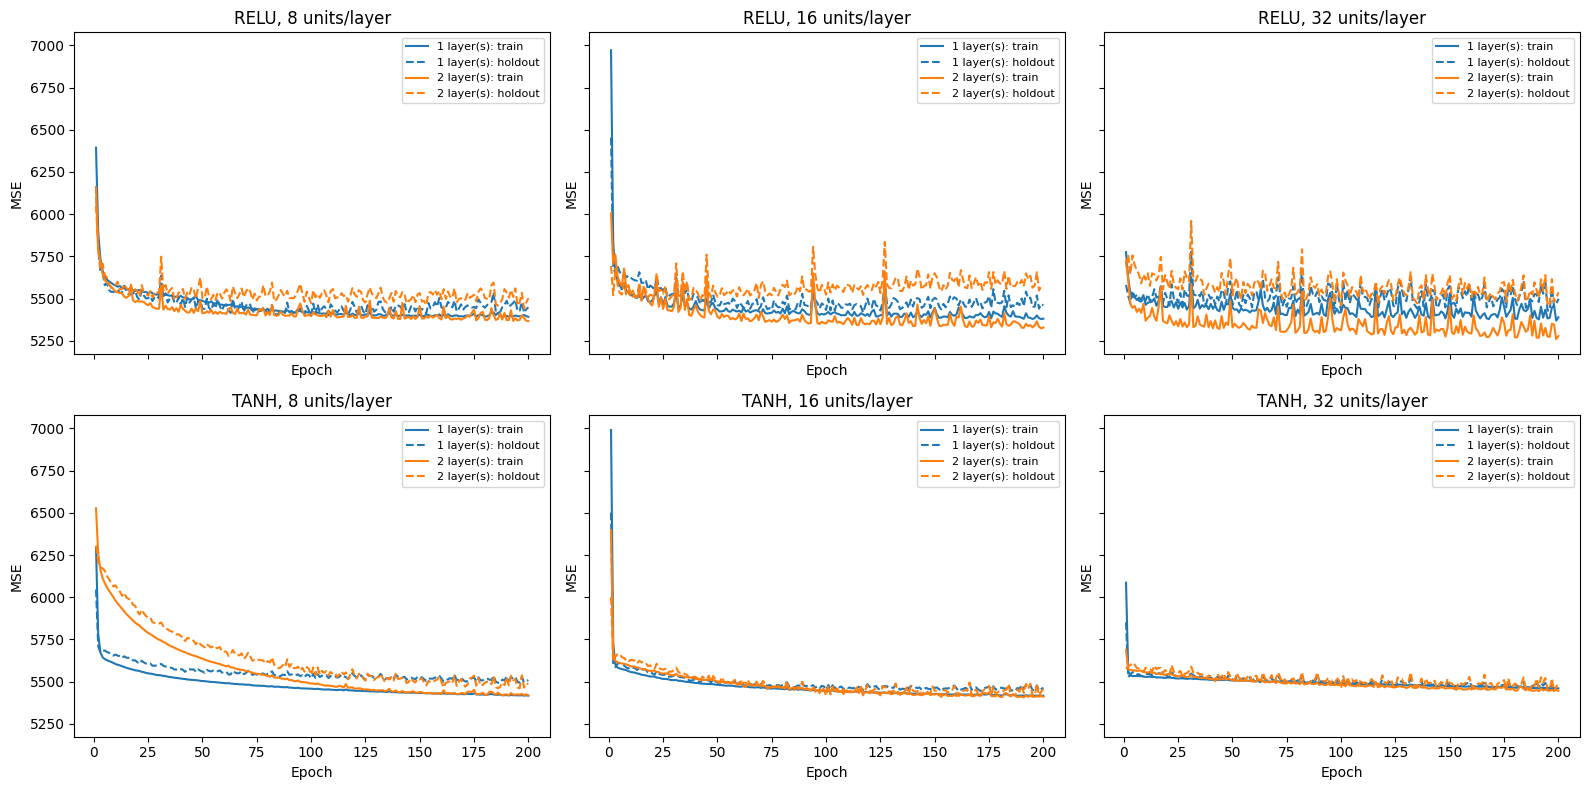

In [4]:
# plotting the learning curves
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8),
    sharex=True,
    sharey=True
)

# converting standardized target mse to original target mse
target_variance = float(reg_y_scaler.scale_[0] ** 2)

for row, activation in enumerate(["relu", "tanh"]):
    for col, hidden_units in enumerate([8, 16, 32]):
        ax = axes[row, col]

        for n_hidden_layers, color in [(1, "tab:blue"), (2, "tab:orange")]:
            model = reg_models[
                (activation, hidden_units, n_hidden_layers)
            ]

            train_curve = (
                np.array(model.history["train_mse"]) * target_variance
            )
            holdout_curve = (
                np.array(model.history["holdout_mse"]) * target_variance
            )

            epochs = np.arange(1, len(train_curve) + 1)

            ax.plot(
                epochs,
                train_curve,
                color=color,
                label=f"{n_hidden_layers} layer(s): train"
            )
            ax.plot(
                epochs,
                holdout_curve,
                color=color,
                linestyle="--",
                label=f"{n_hidden_layers} layer(s): holdout"
            )

        ax.set_title(f"{activation.upper()}, {hidden_units} units/layer")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Analysis**

1 - How does the number of hidden units affect performance? - increasing the number of hidden units didn't consistently improve the holdout performance. For lone-layer ReLU models holdout MSE increased slightly from 5448.27 with 8 units to 5498.50 with 32 units while 2 layer ReLU models got lower training MSE as width increased without improving holdout MSE. Tanh performed best on the holdout set at 16 units for both depths suggesting that adding more units wasn't neccessarily useful for this dataset

2 - What changes when using two layers instead of one? - for ReLU adding a 2nd hidden layer lowered training MSE at every width but increased the holdout MSE suggesting some more overfitting. For example with 16 units per layer training MSE decreased from 5380.49 to 5328.74 while holdout MSE increased from 5459.38 to 5573.82. For Tanh a second layer kind of improved holdout performance at 8 and 16 units but made it slightly worse at 32 so additional depth didn't give a consistent advantage. 

3 - How does the activation function influence results? - ReLU generally got lower training MSE while Tanh gave smoother learning curves with fewer fluctuations especially in the wider models. Their holdout results were close, where ReLU performed better with one layer at each width while Tanh performed better with two layers at each width. The lowest final holdout MSE was 5448.27 from the one-layer ReLU model with 8 units, but these results come from a single split and initialization so they don't quite establish that ReLU is always better.

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

YOUR TEXT HERE

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

For this lab, our group did a great job at completing all our roles induvidually, but struggled to work collaboratively across the entire process. We did some, but not enough, comparing and explaining of our results, so we walked away from this lab with an in-depth understanding of the task we worked with, but not neccessarily a deep enough understanding of the others. Next time, if a lab is split up into distinct sections like this, I think we will try to work collaboratively through each of them together, instead of dividing up the sections for induvidual people to focus on. That way, we can all have a solid understanding of all parts of the lab, instead of just the ones we focused on. 